# RP2 — Drugs, Doses, and Biodistribution
## Math and coding workbook

Your group will work with caffeine, alcohol, and an assigned drug. This notebook supports the applied math part of the project: building a discrete-time model for how a drug-related amount changes in the body.

The notebook has two parts.

**Part I is a read-only toolbox.** It introduces the modeling ideas with small examples. Run these cells and use them as references.

**Part II is your modeling workspace.** You will adapt the code to your assigned drug, generate figures, compute summary quantities, and decide which mathematical ideas belong in the final report.

The report should not be a copied notebook. It should use the notebook results as evidence: equations, figures, computations, and short explanations of modeling choices.

## How to use the notebook

Run the cells in order. In the student workspace, cells marked `TASK` contain values or code that your group should edit. Each `TASK` cell ends with checks that print `PASS` or `NEEDS ATTENTION`. A `NEEDS ATTENTION` message means that a required modeling choice still looks unfinished.

In Part I, time is counted in model steps. In Part II, plots show time in hours, but the number of steps `T`, the dose times, and the rate parameters are still counted per step (see Section 2 and Task 1).

Your goal is not to make the most complicated model possible. Your goal is to make a model that answers a clear question about your assigned drug and to explain what the model can and cannot support.

## Imports

Run the next cell first. It imports the libraries used for calculations and plots, and defines a small check function used later in the workbook.


In [2]:
# Core imports used throughout this workbook.
# numpy handles numerical arrays. matplotlib creates the figures.
import numpy as np
%pip install matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

# Make numerical output easier to read in tables and printed summaries.
np.set_printoptions(precision=4, suppress=True)


def check_item(label, condition, fix=""):
    """Print a non-stopping check message.

    The student notebook is designed to run even before all project choices
    have been finalized. For that reason, this function prints a message
    instead of stopping the notebook with an error.
    """
    if condition:
        print(f"PASS: {label}")
    else:
        print(f"NEEDS ATTENTION: {label}")
        if fix:
            print(f"  Suggested fix: {fix}")


print("Imports loaded. You can now run the read-only technique examples.")


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\lockh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Imports loaded. You can now run the read-only technique examples.


# Part I — Background and techniques

This part is a toolbox. The examples are intentionally small so that each mathematical idea has a clear purpose before you use it in your project.


## 1. What a DTDS does

A discrete-time dynamical system, or DTDS, updates a quantity one step at a time. A one-variable model has the form

$$
A_{t+1}=f(A_t)
$$

The symbol $A_t$ means the modeled amount at step $t$. The function $f$ is the **updating function**: the rule that turns the current amount into the next amount. In this notebook, lowercase $f$ always means the updating function, and uppercase $F$ means bioavailability (defined below).

A useful bookkeeping idea is

$$
A_{t+1}=A_t+F D_t-R_t+M_t
$$

Here, $D_t$ is the dose (input) given during step $t$, $R_t$ is the amount removed during the step, and $M_t$ is the net amount moved in from another part of the model. The **bioavailability** $F$, with $0\le F\le 1$, is the fraction of the dose that reaches the modeled amount. For example, part of an oral dose may never reach the bloodstream. Not every model uses every term.

The simplest removal rule is **first-order removal**: the same fraction of the current amount is removed every step, so $R_t=(1-\rho)A_t$, where the **retention fraction** $\rho$ satisfies $0<\rho<1$. With no transfer term, the bookkeeping equation becomes

$$
A_{t+1}=\rho A_t+F D_t
$$

This is the baseline model used in Part II. Because the update depends on the dose as well as on the current amount, we also write it as $A_{t+1}=f(A_t,D_t)$ with $f(A,D)=\rho A+F D$. In Task 4 you will write your own updating function $f$ for your final model.

## 2. Half-life and the retention fraction

Sources usually describe first-order removal with a **half-life** $t_{1/2}$, the time it takes for the amount to fall by half, or with an **elimination rate constant** $k$, measured per hour. The model needs the retention fraction $\rho$ for one step of length $\Delta t$.

With no new input, $A_{t+n}=\rho^n A_t$. A half-life of $t_{1/2}$ hours is $t_{1/2}/\Delta t$ steps, so $\rho$ must satisfy $\rho^{\,t_{1/2}/\Delta t}=\tfrac12$. Solving gives

$$
\rho=2^{-\Delta t/t_{1/2}}
$$

If a source gives $k$ instead, use $\rho=e^{-k\,\Delta t}$. The two formulas agree because $k=\ln 2/t_{1/2}$.

For example, with $t_{1/2}=5$ hours and $\Delta t=1$ hour, $\rho=2^{-1/5}\approx 0.871$: about 87% of the amount is kept and about 13% is removed each hour.

The helper function `rho_from_half_life` expects the half-life measured in **steps**. That is why Part II divides the half-life in hours by `time_step_hours`.

**Every other rate parameter in this notebook is per step.** The absorption fraction $k_{\mathrm{abs}}$, the maximum removal $V_{\max}$, and the transfer fractions $k_{xy}$ and $k_{yx}$ all describe what happens in one step. Task 3 converts the baseline half-life for you. In Task 4, convert any other half-life yourself with `rho_from_half_life(half_life_hours / time_step_hours)`. If you change the time step, you must also change these parameters.

## 3. Amounts and concentrations

The models in this notebook track an **amount** of drug, for example in mg. Many published values are **concentrations** instead, for example a plasma concentration in mg/L, a therapeutic range, or a toxic level. The link between the two is the **volume of distribution** $V_d$:

$$
C=\frac{A}{V_d}\qquad\text{or equivalently}\qquad A=C\,V_d
$$

$V_d$ is an apparent volume: the volume that would be needed to hold the whole amount in the body at the concentration measured in plasma. A drug that moves into tissues or fat can have a $V_d$ much larger than the volume of blood. Sources often report $V_d$ per kilogram of body mass (L/kg). Multiply by a body mass to get liters.

Use this conversion whenever a threshold, or a parameter such as $K_m$ (Section 7), is reported as a concentration. When a model tracks a single amount in the body, the concentration curve has the same shape as the amount curve, divided by $V_d$.

## Read-only helper functions

The next two cells define the functions used throughout the notebook. They are commented so that you can see the programming ideas: arrays store time-dependent values, loops apply update rules one step at a time, and plotting functions turn arrays into figures.


In [3]:
def rho_from_half_life(half_life_steps):
    """Convert a half-life into a one-step retention fraction.

    If the half-life is h steps, then after h updates the amount should be
    half as large. We therefore solve rho**h = 1/2, which gives
    rho = 2**(-1/h).
    """
    half_life_steps = float(half_life_steps)
    if half_life_steps <= 0:
        raise ValueError("half_life_steps must be positive.")
    return 2.0 ** (-1.0 / half_life_steps)


def half_life_from_rho(rho):
    """Convert a one-step retention fraction back into a half-life in steps.

    This reverses rho_from_half_life: if rho**h = 1/2, then
    h = -log(2) / log(rho).
    """
    rho = float(rho)
    if not (0 < rho < 1):
        raise ValueError("rho must be strictly between 0 and 1.")
    return -np.log(2.0) / np.log(rho)


def iterate_map(f, x0, n_steps):
    """Iterate a one-variable DTDS x_next = f(x_current)."""
    values = np.zeros(n_steps + 1, dtype=float)
    values[0] = float(x0)
    for t in range(n_steps):
        values[t + 1] = f(values[t])
    return values


def make_input_array(T, input_events):
    """Create an input array from a list of time-indexed events.

    Parameters
    ----------
    T : int
        Number of update steps (not hours). The model has amount values at
        steps 0, 1, ..., T and input intervals 0, 1, ..., T-1.
    input_events : list of tuples
        Each tuple has the form (time_index, amount). time_index is a step
        number, not a time in hours. An event at time_index t is added
        during the update from step t to step t + 1.
    """
    T = int(T)
    if T <= 0:
        raise ValueError("T must be a positive integer.")

    D = np.zeros(T, dtype=float)
    for event_time, amount in input_events:
        event_time = int(event_time)
        amount = float(amount)
        if event_time < 0 or event_time >= T:
            raise ValueError(f"Input event time {event_time} is outside 0 to {T-1}.")
        if amount < 0:
            raise ValueError("Input amounts should be non-negative for this workbook.")
        D[event_time] += amount
    return D


def plot_input_schedule(D, time_step_hours=1.0, title="Input schedule", units="model units"):
    """Plot the input events as vertical lines.

    This plot shows when the modeled input is added. It does not show how
    much is in the body after absorption and elimination. That happens in
    the simulation plots.
    """
    D = np.asarray(D, dtype=float)
    times = np.arange(len(D)) * time_step_hours
    fig, ax = plt.subplots(figsize=(8, 3))
    event_mask = D > 0
    ax.vlines(times[event_mask], 0, D[event_mask], linewidth=2)
    ax.scatter(times[event_mask], D[event_mask], zorder=3)
    ax.set_xlabel("time (hours)")
    ax.set_ylabel(f"input ({units})")
    ax.set_title(title)
    if np.any(event_mask):
        ax.set_ylim(0, 1.15 * np.max(D[event_mask]))
    ax.grid(True, alpha=0.3)
    plt.show()


def plot_amount(t, A, D=None, threshold=None, title="Amount over time", ylabel="amount",
                xlabel="time", threshold_label="threshold of interest"):
    """Plot a modeled amount and mark input times if an input array is provided."""
    t = np.asarray(t, dtype=float)
    A = np.asarray(A, dtype=float)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(t, A, marker="o", label=ylabel)

    if threshold is not None:
        ax.axhline(float(threshold), linestyle="--", label=threshold_label)

    if D is not None:
        D = np.asarray(D, dtype=float)
        # Label positions: x is a time on the axis, y is a fraction of the
        # plot height. This keeps the labels inside the plot for any amounts.
        label_position = ax.get_xaxis_transform()
        for j, amount in enumerate(D):
            if amount > 0 and j < len(t):
                # A dotted vertical line marks when input was added.
                ax.axvline(t[j], linestyle=":", alpha=0.35)
                ax.text(t[j], 0.96, f"input {amount:g}", transform=label_position,
                        rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()


def plot_two_amounts(t, first, second, first_label, second_label, title,
                     xlabel="time", ylabel="amount"):
    """Plot two modeled amounts on the same time axis."""
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(t, first, marker="o", label=first_label)
    ax.plot(t, second, marker="s", label=second_label)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()


def plot_removal_per_step(t, removed, Vmax=None, title="Amount removed during each step",
                          xlabel="time", ylabel="amount removed per step"):
    """Plot how much was removed during each update step.

    removed has one value per step, so each value is plotted at the start
    time of its step. A dashed line marks the maximum removal per step, Vmax.
    """
    t = np.asarray(t, dtype=float)
    removed = np.asarray(removed, dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(t[:len(removed)], removed, marker="o", label="amount removed during step")
    if Vmax is not None:
        ax.axhline(float(Vmax), linestyle="--", label="maximum removal per step (Vmax)")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()


def cobweb_plot(f, x0, n_steps=15, x_min=0.0, x_max=50.0, title="Cobweb diagram"):
    """Draw a cobweb diagram for a one-variable autonomous DTDS.

    Use this only when the same updating function f is applied at every step.
    The vertical segment moves from the diagonal to the graph of f.
    The horizontal segment moves from the graph of f back to the diagonal.
    """
    xx = np.linspace(x_min, x_max, 400)
    yy = np.array([f(x) for x in xx], dtype=float)

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot(xx, yy, label="updating function f")
    ax.plot(xx, xx, linestyle="--", label="diagonal")

    current = float(x0)
    for _ in range(n_steps):
        next_value = float(f(current))
        ax.plot([current, current], [current, next_value], linewidth=1)
        ax.plot([current, next_value], [next_value, next_value], linewidth=1)
        current = next_value

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(x_min, x_max)
    ax.set_xlabel("current amount")
    ax.set_ylabel("next amount")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()


def first_time_above(t, A, threshold):
    """Return the first time when A is above the threshold.

    Returns None if A never rises above the threshold in the simulated window.
    """
    if threshold is None:
        return None
    t = np.asarray(t, dtype=float)
    A = np.asarray(A, dtype=float)
    above = np.where(A > float(threshold))[0]
    if len(above) == 0:
        return None
    return float(t[int(above[0])])


def first_time_below_after_peak(t, A, threshold):
    """Return the first time after the peak when A is at or below a threshold.

    Starting the search at the peak avoids counting the initial value, which
    may already be below the threshold before any input has been added.

    Returns None if A never rises above the threshold (so there is nothing to
    fall below), or if A is still above the threshold at the end of the
    simulated window.
    """
    if threshold is None:
        return None
    t = np.asarray(t, dtype=float)
    A = np.asarray(A, dtype=float)
    if np.max(A) <= float(threshold):
        return None
    peak_index = int(np.argmax(A))
    below = np.where(A[peak_index:] <= float(threshold))[0]
    if len(below) == 0:
        return None
    return float(t[peak_index + int(below[0])])


def time_above_threshold(t, A, threshold):
    """Approximate the total time that A spends above the threshold.

    Each model value above the threshold counts for one time step. This is
    an approximation because the model only gives values at the step times.
    """
    if threshold is None:
        return None
    t = np.asarray(t, dtype=float)
    A = np.asarray(A, dtype=float)
    if len(t) < 2:
        return 0.0
    step = float(t[1] - t[0])
    return float(np.sum(A > float(threshold)) * step)


def amount_summary(t, A, threshold=None):
    """Compute report-ready summary values for a modeled amount.

    The threshold values are included only when a threshold is given.
    """
    t = np.asarray(t, dtype=float)
    A = np.asarray(A, dtype=float)
    peak_index = int(np.argmax(A))
    summary = {
        "initial": float(A[0]),
        "peak": float(A[peak_index]),
        "time_at_peak": float(t[peak_index]),
        "final": float(A[-1]),
    }
    if threshold is not None:
        summary["first_time_above_threshold"] = first_time_above(t, A, threshold)
        summary["time_below_threshold_after_peak"] = first_time_below_after_peak(t, A, threshold)
        summary["total_time_above_threshold"] = time_above_threshold(t, A, threshold)
    return summary


def print_summary(summary, label="model"):
    """Print a dictionary returned by amount_summary in a readable form.

    A value of None means the event does not happen within the simulated
    window, for example because the amount never rises above the threshold.
    """
    print(f"Summary for {label}")
    for key, value in summary.items():
        if value is None:
            value = "not reached in the simulated window"
        print(f"  {key}: {value}")

In [42]:
def simulate_one_compartment(rho, D, F=1.0, A0=0.0):
    """Simulate a direct-input, one-compartment model (the baseline model).

    Model idea:
        amount next = retained amount now + immediately available input

    Formula:
        A_next = rho*A_current + F*D_current

    D_current is the input during the current step. F is the bioavailability:
    the fraction of the input that reaches the modeled amount.
    """
    D = np.asarray(D, dtype=float)
    T = len(D)
    A = np.zeros(T + 1, dtype=float)
    A[0] = float(A0)

    for t in range(T):
        A[t + 1] = rho * A[t] + F * D[t]

    return np.arange(T + 1), A

def simulate_absorption_model (k_abs, rho, D, F=1.0, G0= 0.0, A0=0.0):
    """Simulate a reservoir absorption model.

    Variables:
        G is the amount waiting to be absorbed, such as an oral-dose reservoir.
        A is the modeled absorbed amount in the body.

    During each step, new input is added to the reservoir. A fraction k_abs
    of the reservoir is absorbed (k_abs is a fraction per step), and a
    fraction F (the bioavailability) of the absorbed amount contributes to A.
    """
    D = np.asarray(D, dtype=float)
    T = len(D)
    G = np.zeros(T + 1, dtype=float)
    A = np.zeros(T + 1, dtype=float)
    G[0] = float(G0)
    A[0] = float(A0)

    if not (0 <= k_abs <= 1):
        raise ValueError("k_abs must be between 0 and 1.")

    for t in range(T):
        reservoir_available = G[t] + D[t]
        absorbed = k_abs * reservoir_available
        G[t + 1] = reservoir_available - absorbed
        A[t + 1] = rho * A[t] + F * absorbed

    return np.arange(T + 1), A, {"reservoir": G}


def simulate_capacity_limited_model(Vmax, Km, D, F=1.0, A0=0.0):
    """Simulate a one-compartment model with capacity-limited removal.

    In a first-order model, the same fraction is removed each step. Here,
    removal increases with amount but approaches a maximum amount Vmax per
    step. This can represent a process that becomes saturated.

    Vmax is the maximum amount removed per step (amount units per step).
    Km is the amount at which removal is half of Vmax (amount units).
    For small amounts, removal is about (Vmax/Km)*amount, which behaves like
    first-order removal with retention fraction 1 - Vmax/Km.
    """
    D = np.asarray(D, dtype=float)
    T = len(D)
    A = np.zeros(T + 1, dtype=float)
    removed_each_step = np.zeros(T, dtype=float)
    A[0] = float(A0)

    if Vmax <= 0 or Km <= 0:
        raise ValueError("Vmax and Km must be positive.")

    for t in range(T):
        available = A[t] + F * D[t]
        proposed_removed = Vmax * available / (Km + available)
        removed = min(proposed_removed, available)
        A[t + 1] = available - removed
        removed_each_step[t] = removed

    return np.arange(T + 1), A, {"removed_each_step": removed_each_step}


def simulate_linked_compartments(rho_x, rho_y, k_xy, k_yx, D, F=1.0, X0=0.0, Y0=0.0):
    """Simulate two linked compartments.

    This flexible model can be used in two different ways.

    Storage interpretation:
        X is the central amount and Y is a storage amount.
        Use k_yx greater than zero to allow return from storage.

    Product interpretation:
        X is a parent drug and Y is a metabolite or active product.
        Use k_yx equal to zero if the product does not return to X.

    Each step, a fraction k_xy of X moves to Y and a fraction k_yx of Y moves
    back to X (both are fractions per step). Of the amount that stays in X,
    a fraction rho_x is retained. Y retains a fraction rho_y.

    When nothing returns from Y, the overall retention of X per step is
    rho_x * (1 - k_xy), not rho_x. Matching these parameters to published
    values can be challenging (see Section 8).
    """
    D = np.asarray(D, dtype=float)
    T = len(D)
    X = np.zeros(T + 1, dtype=float)
    Y = np.zeros(T + 1, dtype=float)
    X[0] = float(X0)
    Y[0] = float(Y0)

    for value, name in [(rho_x, "rho_x"), (rho_y, "rho_y"), (k_xy, "k_xy"), (k_yx, "k_yx")]:
        if value < 0 or value > 1:
            raise ValueError(f"{name} must be between 0 and 1.")

    for t in range(T):
        x_available = X[t] + F * D[t]
        y_available = Y[t]
        transfer_xy = k_xy * x_available
        transfer_yx = k_yx * y_available
        X[t + 1] = rho_x * (x_available - transfer_xy) + transfer_yx
        Y[t + 1] = rho_y * (y_available + transfer_xy - transfer_yx)

    return np.arange(T + 1), X, Y


def simulate_update_rule(f, D, A0=0.0):
    """Simulate a DTDS A_next = f(A_current, D_current) that you write yourself.

    f takes the current state A and the dose D for this step, and returns
    the next state. A0 is the starting state: a single number for a model
    with one state variable, or a list such as [0.0, 0.0] for a model with
    two state variables. f must return the next state in the same form.

    Returns the step numbers and the states. With one state variable the
    states form a one-dimensional array; with several, the array has one
    row per step and one column per state variable.
    """
    D = np.asarray(D, dtype=float)
    A0 = np.asarray(A0, dtype=float)
    states = np.zeros((len(D) + 1,) + A0.shape, dtype=float)
    states[0] = A0
    for t in range(len(D)):
        next_state = np.asarray(f(states[t], D[t]), dtype=float)
        if next_state.shape != A0.shape:
            raise ValueError(
                f"At step {t}, f returned {next_state.size} value(s), but the starting "
                f"state A0 has {A0.size}. f must return the next state in the same form as A0.")
        states[t + 1] = next_state
    return np.arange(len(D) + 1), states

## 4. Toy model: constant input and equilibrium

Suppose the same amount is added every step and the same fraction is retained every step:

$$
A_{t+1}=\rho A_t+d
$$

This is an autonomous one-variable model because the same updating function $f(A)=\rho A+d$ is applied at each step. An equilibrium is a value $A^*$ that stays fixed after an update. It satisfies

$$
A^*=\rho A^*+d
$$

so, when $\rho \neq 1$,

$$
A^*=\frac{d}{1-\rho}
$$

Subtracting the equilibrium equation from the update rule gives $A_{t+1}-A^*=\rho\,(A_t-A^*)$. The distance from equilibrium shrinks by the factor $\rho$ every step, so

$$
A_t=A^*+\rho^{\,t}\,(A_0-A^*)
$$

Because $0<\rho<1$, $\rho^{\,t}\to 0$ and every solution approaches $A^*$. We say that the equilibrium is **stable**.

This equilibrium has a clear interpretation only when the input really is the same every step. 

In an alternate model, when the dose would stop after a single step, the update becomes $A_{t+1}=\rho A_t$. Its only equilibrium is $A^*=0$, so the amount decays toward zero instead of settling at a positive level.

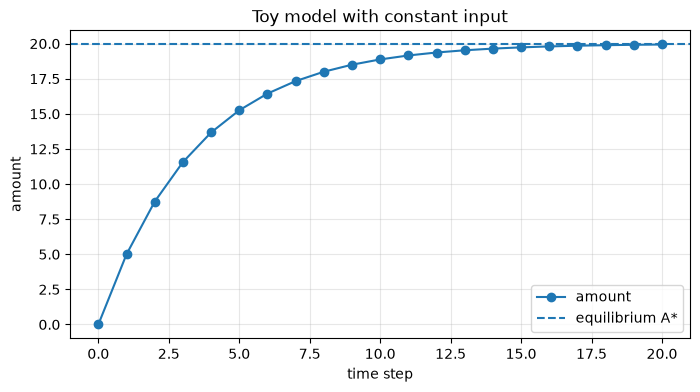

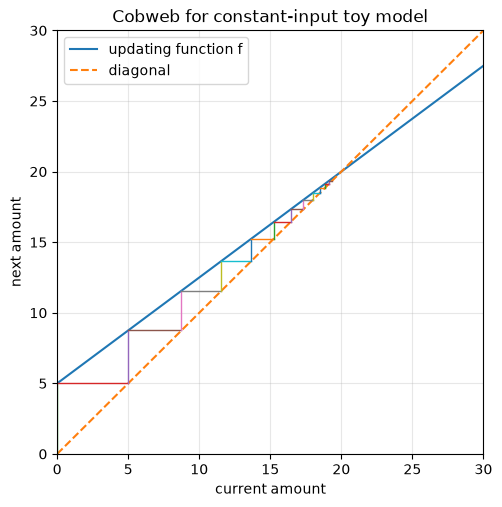

Toy equilibrium: 20.00


In [5]:
# Toy model with constant input.
# The values are chosen to make the behavior easy to see.
rho_toy = 0.75
d_toy = 5.0
f_toy = lambda A: rho_toy * A + d_toy   # the updating function f

toy_amount = iterate_map(f_toy, x0=0.0, n_steps=20)
toy_time = np.arange(len(toy_amount))
toy_equilibrium = d_toy / (1 - rho_toy)

plot_amount(toy_time, toy_amount, threshold=toy_equilibrium,
            threshold_label="equilibrium A*",
            title="Toy model with constant input",
            ylabel="amount", xlabel="time step")

cobweb_plot(f_toy, x0=0.0, n_steps=12, x_min=0.0, x_max=30.0,
            title="Cobweb for constant-input toy model")

print(f"Toy equilibrium: {toy_equilibrium:.2f}")

## 5. Cobweb diagrams and stability

A cobweb diagram is a qualitative picture for a one-variable autonomous DTDS. It uses two curves: the graph of the updating function $y=f(A)$ and the diagonal $y=A$.

To read the cobweb, start with an initial amount on the horizontal axis. Move vertically to the graph of $f$ to find the next amount. Then move horizontally to the diagonal so that this next amount becomes the new current amount. Repeating those two moves shows whether the model moves toward or away from an equilibrium.

Equilibria are where the graph of $f$ crosses the diagonal, because there $f(A^*)=A^*$. The slope of $f$ at that point decides what happens nearby:

- If $|f'(A^*)|<1$, nearby values move toward $A^*$, and the equilibrium is **stable**. A positive slope gives a staircase; a negative slope gives a spiral.
- If $|f'(A^*)|>1$, nearby values move away from $A^*$, and the equilibrium is **unstable**.

For $f(A)=\rho A+d$, the slope is $\rho$ everywhere, so the equilibrium in Section 4 is stable whenever $0<\rho<1$. The cobweb above shows the staircase.

Use a cobweb when the same one-variable updating function is applied every step. Do not use an ordinary cobweb for a scheduled single dose, a changing input schedule, an absorption lag, or a model that tracks two amounts at once. Those cases should usually be shown with time-series plots.

## 6. Toy model: single oral input with absorption

A single oral input is different from constant input. The model has no reason to settle to a positive equilibrium because no new input is added later. For this situation, a time-series plot is usually more meaningful than a cobweb.

A simple absorption model tracks two amounts. Each quantity that a model keeps track of is called a **state variable**, so this model has two state variables. Let $G_t$ be the amount waiting to be absorbed and $A_t$ be the absorbed amount of interest. One possible update rule is

$$
G_{t+1}=(1-k_{\mathrm{abs}})(G_t+D_t)
$$

$$
A_{t+1}=\rho A_t+F k_{\mathrm{abs}}(G_t+D_t)
$$

The parameter $k_{\mathrm{abs}}$ is the fraction of the reservoir absorbed in one step, so $0\le k_{\mathrm{abs}}\le 1$. The bioavailability $F$ is the fraction of absorbed material that contributes to the modeled amount, and $\rho$ is the retention fraction from Section 2.

A larger $k_{\mathrm{abs}}$ makes the peak earlier and higher. Some sources report an absorption rate constant $k_a$, measured per hour. It converts to a fraction per step in the same way as $k$ in Section 2: $k_{\mathrm{abs}}=1-e^{-k_a\,\Delta t}$. More often, sources report $T_{\max}$, the time from the dose to the peak concentration. You can then choose $k_{\mathrm{abs}}$ by adjusting it until the model's time of peak is close to $T_{\max}$.

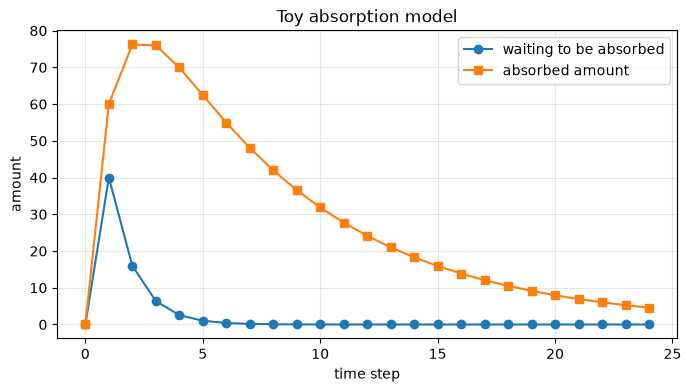

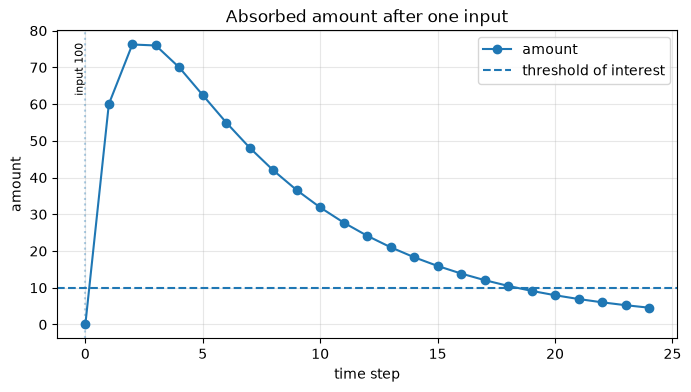

Summary for toy absorption model
  initial: 0.0
  peak: 76.23303379776745
  time_at_peak: 2.0
  final: 4.577211391787279
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 19.0
  total_time_above_threshold: 18.0


In [6]:
# Toy single-input absorption model.
# The input enters a reservoir first, then is absorbed gradually.
T_abs_toy = 24
D_abs_toy = make_input_array(T_abs_toy, [(0, 100.0)])
rho_abs_toy = rho_from_half_life(5.0)
k_abs_toy = 0.60

t_abs_toy, A_abs_toy, extra_abs_toy = simulate_absorption_model(
    k_abs=k_abs_toy,
    rho=rho_abs_toy,
    D=D_abs_toy,
    F=1.0
)

plot_two_amounts(t_abs_toy, extra_abs_toy["reservoir"], A_abs_toy,
                 "waiting to be absorbed", "absorbed amount",
                 "Toy absorption model", xlabel="time step")

plot_amount(t_abs_toy, A_abs_toy, D=D_abs_toy, threshold=10.0,
            title="Absorbed amount after one input",
            ylabel="amount", xlabel="time step")

print_summary(amount_summary(t_abs_toy, A_abs_toy, threshold=10.0),
              label="toy absorption model")


## 7. Toy model: capacity-limited removal

First-order removal assumes that the body removes the same *fraction* every step, however large the amount. Some removal processes, such as an enzyme or a transporter, can become saturated: once they are working at full capacity, a larger amount is not removed any faster. A common model for this is Michaelis–Menten removal. Let $B_t=A_t+F D_t$ be the amount available during step $t$. Then

$$
A_{t+1}=B_t-\frac{V_{\max}\,B_t}{K_m+B_t}
$$

- $V_{\max}$ is the maximum amount that can be removed in one step (amount units per step).
- $K_m$ is the amount at which removal is half of its maximum (amount units).

The read-only helper function for this model also makes sure that removal never exceeds the amount available. A rule that you write yourself in Task 4 does not do this automatically.

Two limits explain the behavior:

- **Large amounts** ($B_t$ much larger than $K_m$): removal is close to $V_{\max}$, a constant *amount* per step, so the amount falls almost in a straight line. Sources call this **zero-order** removal.
- **Small amounts** ($B_t$ much smaller than $K_m$): removal is close to $(V_{\max}/K_m)\,B_t$, a constant *fraction* per step. This is first-order removal with retention fraction $\rho\approx 1-V_{\max}/K_m$.

So, compared with a first-order model that behaves the same at small amounts, a capacity-limited model removes the drug more slowly while the amount is high, and the amount stays high for longer. Unlike the other models in this notebook, it is **nonlinear** (Section 9).

Sources usually report $K_m$ as a concentration. Convert it to an amount by multiplying by $V_d$ (Section 3). If $V_{\max}$ is given as an amount per hour, multiply by the time step in hours to get the amount per step. If it is given as a concentration per time (for example mg/L per hour), also multiply by $V_d$. If it is given per day or per kg of body mass, convert to hours and to a whole body first.

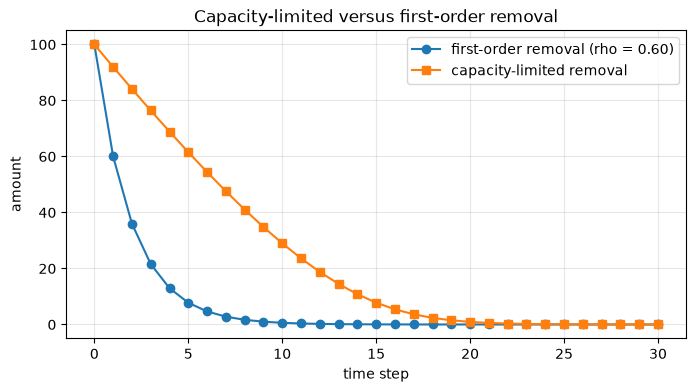

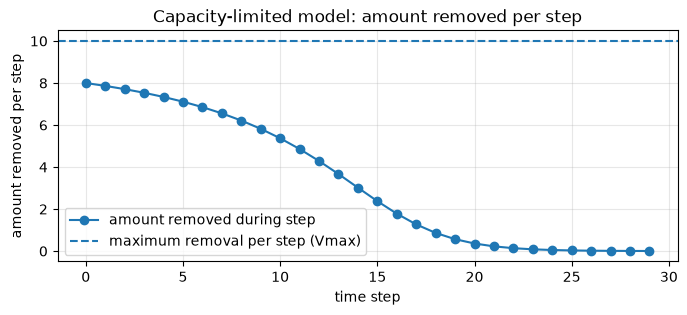

In [7]:
# Toy capacity-limited removal model.
# Start with 100 units already in the body (A0 = 100) and give no further
# input. Compare with first-order removal that behaves the same way once
# the amount is small, that is, with rho = 1 - Vmax/Km.
T_capacity_toy = 30
no_input_toy = make_input_array(T_capacity_toy, [])
Vmax_toy = 10.0                       # maximum amount removed per step
Km_toy = 25.0                         # amount at which removal is half of Vmax_toy
rho_low_toy = 1 - Vmax_toy / Km_toy   # first-order retention at small amounts

t_capacity_toy, A_capacity_toy, extra_capacity_toy = simulate_capacity_limited_model(
    Vmax=Vmax_toy, Km=Km_toy, D=no_input_toy, A0=100.0)
t_first_order_toy, A_first_order_toy = simulate_one_compartment(
    rho=rho_low_toy, D=no_input_toy, A0=100.0)

plot_two_amounts(t_capacity_toy, A_first_order_toy, A_capacity_toy,
                 f"first-order removal (rho = {rho_low_toy:.2f})",
                 "capacity-limited removal",
                 "Capacity-limited versus first-order removal",
                 xlabel="time step")

# While the amount is large, close to Vmax is removed each step, so the
# amount falls almost in a straight line. Once the amount is small, the
# removal shrinks in proportion to the amount, as in first-order removal.
plot_removal_per_step(t_capacity_toy, extra_capacity_toy["removed_each_step"],
                      Vmax=Vmax_toy,
                      title="Capacity-limited model: amount removed per step",
                      xlabel="time step")

## 8. Advanced: a model with two linked compartments

This section is optional. It shows, in an abstract way, how a model can track two amounts that feed into each other. You do not need it for the project (see Task 4).

A linked-compartment model tracks two amounts, $X_t$ and $Y_t$. Each amount is called a compartment. Each step, a fraction $k_{xy}$ of $X$ moves to $Y$, and a fraction $k_{yx}$ of $Y$ moves back to $X$. Of the amount that stays in $X$, a fraction $\rho_x$ is retained, and $Y$ retains a fraction $\rho_y$. Let $B_t=X_t+F D_t$ be the amount available in $X$ during step $t$. Then

$$
X_{t+1}=\rho_x\,(1-k_{xy})\,B_t+k_{yx}\,Y_t
$$

$$
Y_{t+1}=\rho_y\,\big(Y_t+k_{xy}\,B_t-k_{yx}\,Y_t\big)
$$

All four parameters are per step and lie between 0 and 1.

Models of this kind are used when a drug is converted into another active substance, or when it moves into a tissue that stores it and releases it slowly. In both cases the two amounts interact, so the behavior of one compartment cannot be read from a single parameter. For example, $X$ does not decay with retention fraction $\rho_x$ alone, because it also loses amount to $Y$ and may get some of it back.

**Why this is advanced.** Matching the parameters of a linked model to values in the literature can be challenging. Sources may not directly report the transfer parameters in the form this model needs, and a published half-life or volume of distribution may describe the drug in the body as a whole, not one compartment of a model.

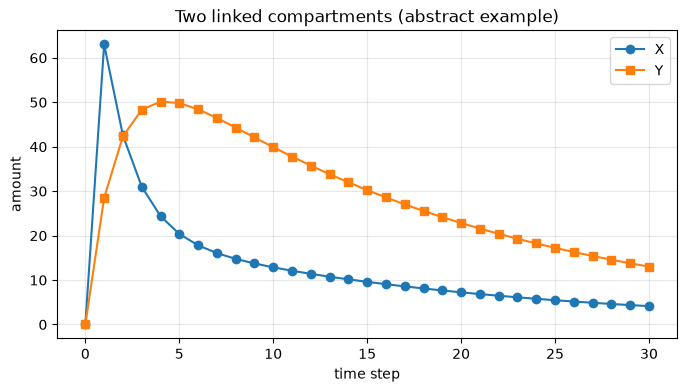

In [8]:
# Abstract example of two linked compartments (optional, advanced).
# X receives one input of 100 at step 0. Each step, 30% of X moves to Y and
# 10% of Y moves back to X. Each compartment also loses a little of what it
# holds: X retains 90% and Y retains 95%.
T_linked_toy = 30
D_linked_toy = make_input_array(T_linked_toy, [(0, 100.0)])

t_linked_toy, X_toy, Y_toy = simulate_linked_compartments(
    rho_x=0.90, rho_y=0.95, k_xy=0.30, k_yx=0.10,
    D=D_linked_toy, F=1.0)

plot_two_amounts(t_linked_toy, X_toy, Y_toy, "X", "Y",
                 "Two linked compartments (abstract example)", xlabel="time step")

# X falls quickly at first, while much of it moves to Y. Later it falls more
# slowly, because Y keeps returning some amount to X.

## 9. Linear and nonlinear models

The baseline, absorption, and linked models are **linear**: each update multiplies the current amounts by constants and adds the input. For a linear model that starts with nothing in the body, this has two consequences:

- Multiplying every dose by a factor $c$ multiplies the whole output curve by $c$. The peak is $c$ times higher but happens at the same time, and the shape of the curve does not change.
- Doses add: the curve for two doses is the sum of the curves for each dose given on its own.

The capacity-limited model is **nonlinear** because its removal term $V_{\max}B/(K_m+B)$ is not proportional to $B$. Changing the dose can change the shape of the curve, not just its height.

This matters for the sensitivity comparison in Task 6. For a linear model, a dose change only rescales the curve. It still changes when the amount crosses a threshold, but it cannot change the time of the peak. Changing a half-life, the absorption speed, or the dose timing tests a linear model in a different way.

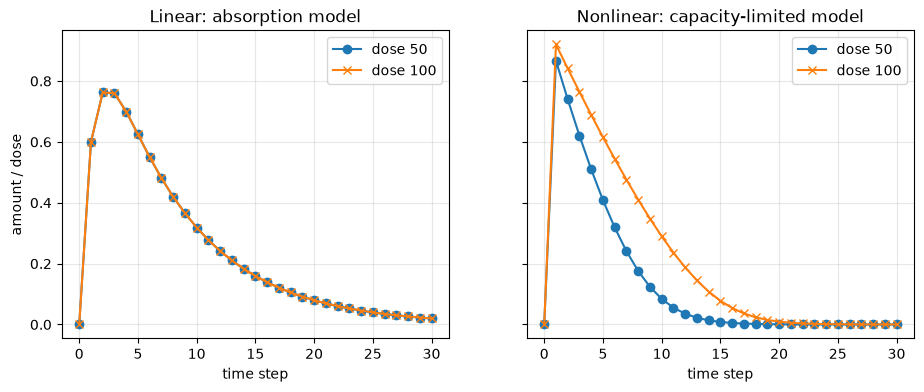

In [9]:
# Linear versus nonlinear: give a dose of 50 and a dose of 100 to each model,
# then divide each curve by its dose. For a linear model the two scaled
# curves are identical. For a nonlinear model they are not.
T_scaling_toy = 30
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for dose, marker in [(50.0, "o"), (100.0, "x")]:
    D_scaling_toy = make_input_array(T_scaling_toy, [(0, dose)])
    t_scaling_toy, A_linear_toy, _ = simulate_absorption_model(
        k_abs=0.6, rho=rho_from_half_life(5.0), D=D_scaling_toy)
    _, A_nonlinear_toy, _ = simulate_capacity_limited_model(
        Vmax=10.0, Km=25.0, D=D_scaling_toy)
    axes[0].plot(t_scaling_toy, A_linear_toy / dose, marker=marker, label=f"dose {dose:g}")
    axes[1].plot(t_scaling_toy, A_nonlinear_toy / dose, marker=marker, label=f"dose {dose:g}")

axes[0].set_title("Linear: absorption model")
axes[1].set_title("Nonlinear: capacity-limited model")
axes[0].set_ylabel("amount / dose")
for ax in axes:
    ax.set_xlabel("time step")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()

## 10. Choosing a final model feature

In the project workspace, the **baseline model** (immediate input and first-order removal, Section 1) is required. It is simple and gives a comparison point. Your final model should add **one** feature that is motivated by what is known about your assigned drug. In Task 4 you write the update rule for this feature yourself; Sections 6–8 show how each feature below can be written as an update rule.

| Final feature | Consider it when your sources say… | What to look up | Main output |
|---|---|---|---|
| Absorption reservoir (Section 6) | The drug is taken by a route that delays its arrival, for example by mouth, or the peak concentration comes noticeably later than the dose | half-life, bioavailability $F$, time to peak $T_{\max}$ (used to choose $k_{\mathrm{abs}}$) | amount waiting to be absorbed and absorbed amount |
| Capacity-limited removal (Section 7) | Removal is saturable or dose-dependent, it is described as zero-order or Michaelis–Menten, or the half-life gets longer at higher doses | $V_{\max}$, $K_m$ (often a concentration: convert with $V_d$), typical doses | amount over time |
| Linked compartments (Section 8): **advanced and optional** | The drug is converted into an active or important metabolite, or it is stored in a tissue such as fat and released slowly | half-lives of both forms, the fraction converted or stored, the rate of return from storage; these are hard to match to published values | two related amounts over time |

Choose the feature that best matches your assigned drug and your modeling question. If more than one fits, choose the one that matters most for your question and mention the others as limitations. The linked-compartment feature is an optional extra challenge: you never have to choose it, even when it is relevant to your assigned drug (see Task 4). Repeated dosing is allowed when it fits the scenario, but it is not required.

Whatever you choose, you will probably also need a typical dose, the half-life, and the bioavailability $F$. If your threshold or parameters are concentrations, you will also need the volume of distribution $V_d$ (Section 3).

# Part II — Your modeling workspace

The cells below produce material for the final report. Instead of answering long questions inside Markdown cells, use the computations and figures to support your report narrative.


## Task 1 — Define the scenario

Decide what the model is trying to explain. Keep the assigned drug in mind, but choose a focused scenario. A focused scenario is usually more useful than a broad model that tries to include every physiological detail.

**Report issues to address:** state the drug, the model question, the time step, the modeled amount and units, the input scenario, and the threshold of interest. Explain what the threshold represents and where it comes from. Avoid calling it a safety threshold unless you have a source and the course team has approved that language.

**Time units.** `T` is a number of steps, not hours. The simulated window is `T × time_step_hours` hours. If you change `time_step_hours`, change `T` as well, and remember that the per-step parameters in Task 4 must change too (Section 2).

**Choosing the time step.** A dose given at step $t$ first appears in the modeled amount at step $t+1$, and the model only reports values at whole steps. With a 1-hour step, no peak can come earlier than 1 hour after the dose, and every reported time is a whole number of hours. Choose `time_step_hours` small enough for the fastest process in your scenario: about a quarter of $T_{\max}$ (or of the shortest half-life) or less. For example, if $T_{\max}$ is 1 hour, use a step of 0.25 hours and increase `T` to cover the same window.

**Thresholds given as concentrations.** If your source gives the threshold as a concentration, for example in mg/L, enter it as `threshold_concentration` together with a volume of distribution, and the cell converts it to an amount (Section 3).

In [26]:
# === TASK 1: define your modeling scenario ===
# Replace the EDIT_ME text. The numerical defaults are only placeholders
# so that the notebook runs before your group has finalized its choices.

assigned_drug = "Alprazolam"
model_question = "How does the amount of 0.5mg of Alprazolam, taken orally, change over a 48 hour period"
amount_units = "mg"
time_step_hours = 1  # length of one model step, in hours
T = 48          # number of steps (not hours); window = T * time_step_hours hours

# Threshold of interest, in the same units as the modeled amount.
threshold_amount = 0.1
threshold_note = "Threshold --> minimum amount of a drug required to obtain a detectable physiological effect in an organism comes from --> clinical trials, observing effects at various dosages"

# Optional: if your threshold is a concentration, enter it here with a volume
# of distribution. Use matching units: mg/L times L gives an amount in mg.
# If your source gives V_d in L/kg, multiply by a body mass in kg first.
threshold_concentration = None   # for example in mg/L; None means use threshold_amount
volume_of_distribution = None    # for example in L
if threshold_concentration is not None and volume_of_distribution is not None:
    threshold_amount = threshold_concentration * volume_of_distribution
    print(f"Threshold converted from a concentration: {threshold_amount:g} {amount_units}")

print(f"Simulated window: {T} steps of {time_step_hours:g} h = {T * time_step_hours:g} hours")

check_item("assigned drug has been entered", "EDIT_ME" not in assigned_drug,
           "Replace assigned_drug with the drug your group is modeling.")
check_item("model question has been entered", "EDIT_ME" not in model_question,
           "Write a one-sentence question that the model is meant to answer.")
check_item("amount units have been entered", "EDIT_ME" not in amount_units,
           "Specify the units used for modeled amount.")
check_item("time step is positive", time_step_hours > 0)
check_item("model has at least 12 update steps", T >= 12)
check_item("threshold is non-negative", threshold_amount >= 0)
check_item("threshold note has been entered", "EDIT_ME" not in threshold_note,
           "Explain what the threshold represents and give its source.")
check_item("a concentration threshold has a volume of distribution",
           threshold_concentration is None or volume_of_distribution is not None,
           "Enter volume_of_distribution so the concentration can be converted to an amount.")

Simulated window: 48 steps of 1 h = 48 hours
PASS: assigned drug has been entered
PASS: model question has been entered
PASS: amount units have been entered
PASS: time step is positive
PASS: model has at least 12 update steps
PASS: threshold is non-negative
PASS: threshold note has been entered
PASS: a concentration threshold has a volume of distribution


## Task 2 — Build the input schedule

The input schedule records when material enters the model. For many assigned-drug scenarios, a single input or a short sequence of inputs is enough. Repeated input should be used only when your modeling question actually involves a repeated pattern.

Each event is a pair `(time_index, amount)`. The time index is a step number, not a time in hours: time in hours = time index × `time_step_hours`. For example, a dose at 6 hours with a half-hour time step has time index 12.

**Report issues to address:** explain where the input amounts and timing came from, what route or assumption they represent, and what is uncertain about them.

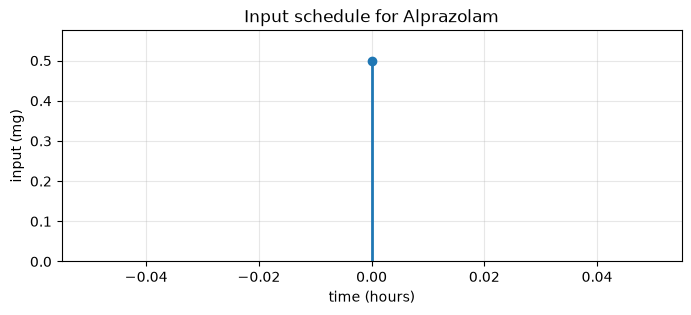

PASS: at least one input event is included
PASS: all input events are non-negative
PASS: input note has been entered


In [28]:
# === TASK 2: build the input schedule ===
# Each tuple is (time_index, amount). time_index is a step number, not hours:
# time in hours = time_index * time_step_hours. A time_index of 0 means the
# input is added during the update from step 0 to step 1.
# For a single-dose scenario, use one tuple. For a short multi-dose
# scenario, add more tuples.

input_events = [(0, 0.5)]
input_note = "This represents an oral dosage of Alprazolam, a singular 0.5mg dose is administered at 0 hours. 0.5mg was chosen as it is a commonly perscribed dosage"

D = make_input_array(T, input_events)
time_values = np.arange(T + 1) * time_step_hours

plot_input_schedule(D, time_step_hours=time_step_hours,
                    title=f"Input schedule for {assigned_drug}",
                    units=amount_units)

check_item("at least one input event is included", np.sum(D) > 0,
           "Add at least one event to input_events.")
check_item("all input events are non-negative", np.all(D >= 0))
check_item("input note has been entered", "EDIT_ME" not in input_note,
           "Explain the source of the dose amounts and timing, and the route they represent.")

## Task 3 — Baseline model

The baseline model is

$$
A_{t+1}=\rho A_t+F D_t
$$

It assumes immediate availability and first-order removal (Sections 1 and 2), with bioavailability $F$. This model may be too simple for your final answer, but it gives a comparison point.

**Report issues to address:** give the equation, define each variable and parameter, justify the half-life (or retention fraction) and the bioavailability, and explain one limitation of the baseline model for your assigned drug.

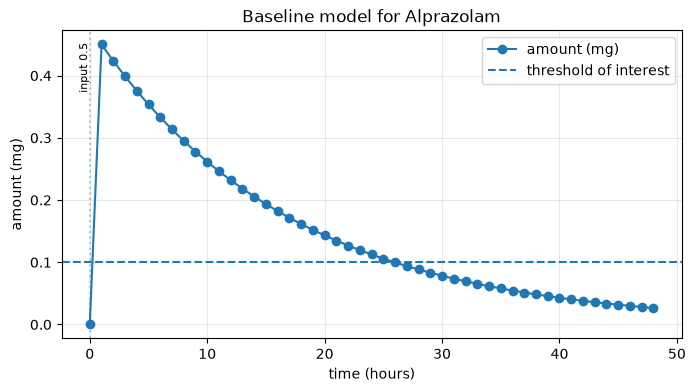

Summary for baseline model
  initial: 0.0
  peak: 0.45
  time_at_peak: 1.0
  final: 0.02647987982293754
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 26.0
  total_time_above_threshold: 25.0
rho_baseline = 0.9415
PASS: baseline half-life is positive
PASS: baseline bioavailability is between 0 and 1
PASS: baseline parameter note has been completed


In [27]:
# === TASK 3: baseline model ===
# The baseline assumes input reaches the modeled amount immediately and
# that the same fraction is retained each time step.

baseline_half_life_hours = 11.5
baseline_bioavailability = 0.9  # F: fraction of each dose that reaches the modeled amount
baseline_parameter_note = "Generally, bioavailability of Alprazolam is %80-%100 (Greenblatt, Wright 2012), "
"90% was chosen as it was the mean of these values. The half-life of Alprazolam ranges from 9-16 hours (Greenblatt, Wright 2012)."
"so the mean, 11.5 hours, was chosen"

rho_baseline = rho_from_half_life(baseline_half_life_hours / time_step_hours)

t_base, A_base = simulate_one_compartment(
    rho=rho_baseline,
    D=D,
    F=baseline_bioavailability,
    A0=0.0
)

plot_amount(t_base * time_step_hours, A_base, D=D, threshold=threshold_amount,
            title=f"Baseline model for {assigned_drug}",
            ylabel=f"amount ({amount_units})", xlabel="time (hours)")

baseline_summary = amount_summary(t_base * time_step_hours, A_base, threshold=threshold_amount)
print_summary(baseline_summary, label="baseline model")
print(f"rho_baseline = {rho_baseline:.4f}")

check_item("baseline half-life is positive", baseline_half_life_hours > 0)
check_item("baseline bioavailability is between 0 and 1",
           0 <= baseline_bioavailability <= 1)
check_item("baseline parameter note has been completed", "EDIT_ME" not in baseline_parameter_note,
           "Add a source-based or clearly justified note for your baseline parameters.")

## Task 4 — Final model: write your own updating function

Your final model is the baseline model plus **one** feature from the table in Section 10. In this task you write its update rule yourself, as a Python function `f`:

$$
A_{t+1}=f(A_t,D_t)
$$

Here $A_t$ is the state at step $t$, $D_t$ is the dose given during step $t$, and $f$ returns the next state. The cell starts with the baseline model, $f(A,D)=\rho A+F D$, so that it runs. Replace it with your own rule.

1. Write your update rule as an equation on paper first. Sections 6–8 show how each feature in Section 10 can be written as an update rule.
2. Define every parameter at the top of the cell, with its units in a comment. Rate parameters are **per step** (Section 2). Convert a half-life in hours with `rho_from_half_life(half_life_hours / time_step_hours)`.
3. Write `f`. With one state variable, `A` is a single number and `f` returns a single number. With two state variables, such as an absorption reservoir or linked compartments, `A` is a pair of numbers and `f` returns the next pair. Then set `A0_final`, `state_labels`, and `amount_index` to match.

**Optional extra challenge: linked compartments.** A linked-compartment model (Section 8) is advanced, and you are not required to use one, even when it is relevant to your assigned drug. You can choose the absorption or capacity-limited feature instead and describe the linked behavior as a limitation of your model. If you do attempt a linked model, expect that matching its parameters to published values will be challenging, and explain how you chose each value.

The cell simulates your model, plots every state variable and the amount of interest, and checks that your model gives finite, non-negative values that differ from the baseline.

**Report issues to address:** state why the chosen feature belongs in the model, define the state variables, give the update rule $f$ as an equation, and justify the new parameters.

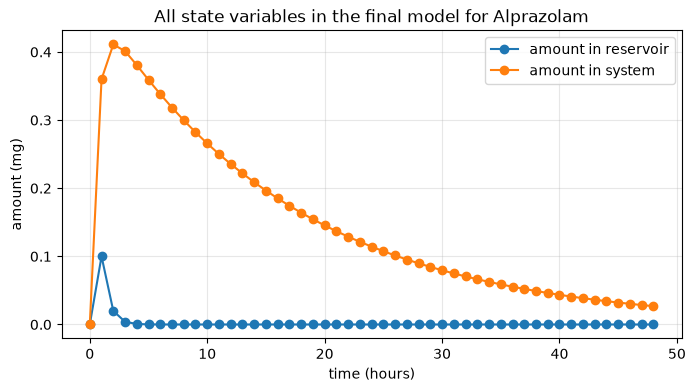

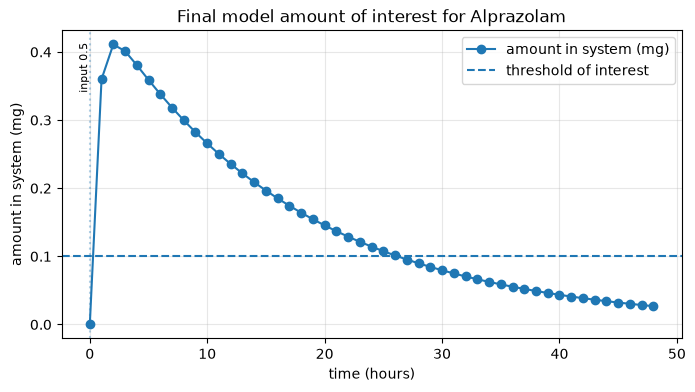

Summary for final model
  initial: 0.0
  peak: 0.4109424617336008
  time_at_peak: 2.0
  final: 0.026897648565339865
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 27.0
  total_time_above_threshold: 26.0
PASS: final parameter note has been completed
PASS: one label for each state variable
PASS: final modeled amounts are finite
PASS: final modeled amounts are non-negative
PASS: final model differs from the baseline


In [111]:
# === TASK 4: write the updating function for your final model ===
# Your final model is A_next = f(A, D): A is the current state and D is the
# dose given during this step. The starting version below is the baseline
# model, so that the notebook runs. Replace it with your own update rule.

final_parameter_note ="the Absorption Reservoir model was chosen to model Alprazolam amounts over time. this is because the medication is normally taken as a single oral input, whose concentration changes over time."

# --- Parameters ---------------------------------------------------------------
# Define every parameter your update rule uses, with its units in a comment.
# Rate parameters are per step. Convert half-lives with rho_from_half_life.
# Warning: the notebook already uses the names D (the dose array) and T (the
# number of steps). Do not give a parameter either name: writing D = 200 or
# T = 2 here would break the cells below. Use names such as dose or T_max.

F = baseline_bioavailability                                     # bioavailability (fraction of each dose)
half_life_hours = 11.5                                           # amount of hours for an amount to decay by half
time_step_hours = 1                                              # length of one step in hours
rho_model = rho_from_half_life(half_life_hours/time_step_hours)  # convert half-life to retention fraction (amount retained each step)
T_model= 48                                                      # total modelled time modeled in hours 
D_model = make_input_array(T_model, [(0,0.5)])                   # amount added (dose administered) to resevoir at each step (set as an array) in mg
kabs_model = 0.80                                                # fraction of available dose absorbed from resevoir in a given step 
G_model = np.zeros(T_model + 1)                                  # amount waiting to be absorbed (set as an array) in mg
G_model[0] = 0.0                                                 # amount of substance in resevoir at t=0 in mg
A_model = np.zeros (T_model + 1)                                 # amount absorbed (set as an array) in mg
A_model[0]= 0.0                                                  # amount of substance absorbed at t=0 in mg

# --- Updating function ----------------------------------------------------------
# Warning: a rule that subtracts a removal term can give negative amounts if
# the time step is too large. For example, capacity-limited removal goes
# negative when Vmax per step is larger than Km. If the check at the end of
# this cell reports negative amounts, use a smaller time_step_hours in Task 1
# and convert your per-step parameters again.
def my_absorption_reservoir():
    """Return the next state from the current state A and the dose D."""
    """for every step, some amount is removed from resevoir (G_model) and added to the absorbed amount (A_model)"""
    for t in range(T_model):                            #for each time step t within the model range, compute the following function...
        reservoir_amt = G_model[t] + D_model[t]         # amount in resevoir is equal to amount waiting to be absorbed at a time - amount
        amt_absorbed= kabs_model * reservoir_amt        # amount absorbed in each step is the fraction of absorbed dose multiplied by 
        G_model[t + 1] = reservoir_amt - amt_absorbed   #amount waiting to be absorbed at a given step, defined by the initial resevoir amount - amount in system
        A_model[t + 1] = (rho_model * A_model[t]) + (F * amt_absorbed) #amount absorbed at a given step, defined by the equation 

    return np.arange(T_model + 1), A_model, {"reservoir":G_model}   #returns a NumPy array for the


# --- State ----------------------------------------------------------------------
# One state variable: A0_final is a single number and f returns one number.
# Two state variables: A0_final is a list such as [0.0, 0.0], and f must
# unpack A and return a list of two numbers. The layout is:

def updating_function(state, dose):
    reservoir, system = state            # current values of the two state variables   

    available = reservoir + dose
    absorbed = kabs_model * available

    reservoir_next = available - absorbed
    system_next = rho_model * system + F * absorbed

    return [reservoir_next, system_next]


A0_final = [0.0, 0.0]                     # starting state
state_labels = ["amount in reservoir", "amount in system"]     # one name per state variable
amount_index = 1                          # state variable compared with the threshold (0 = first)

# --- Simulation -----------------------------------------------------------------
t_final, states_final = simulate_update_rule(f, D_model, A0_final)
states_table = states_final.reshape(len(t_final), -1)   # one column per state variable
n_states = states_table.shape[1]
if not 0 <= amount_index < n_states:
    raise ValueError(f"amount_index must be between 0 and {n_states - 1}.")
amount_final = states_table[:, amount_index]

if n_states > 1:
    # Plot every state variable so you can see how they interact.
    fig, ax = plt.subplots(figsize=(8, 4))
    for j in range(n_states):
        label = state_labels[j] if j < len(state_labels) else f"state variable {j}"
        ax.plot(t_final * time_step_hours, states_table[:, j], marker="o", label=label)
    ax.set_xlabel("time (hours)")
    ax.set_ylabel(f"amount ({amount_units})")
    ax.set_title(f"All state variables in the final model for {assigned_drug}")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

amount_label = state_labels[amount_index] if amount_index < len(state_labels) else "amount"
plot_amount(t_final * time_step_hours, amount_final, D=D_model, threshold=threshold_amount,
            title=f"Final model amount of interest for {assigned_drug}",
            ylabel=f"{amount_label} ({amount_units})", xlabel="time (hours)")

final_summary = amount_summary(t_final * time_step_hours, amount_final, threshold=threshold_amount)
print_summary(final_summary, label="final model")

check_item("final parameter note has been completed", "EDIT_ME" not in final_parameter_note,
           "Explain why this model feature belongs in your assigned-drug scenario.")
check_item("one label for each state variable", len(state_labels) == n_states,
           "Give state_labels one name for each state variable.")
check_item("final modeled amounts are finite", np.all(np.isfinite(states_table)))
check_item("final modeled amounts are non-negative", np.min(states_table) >= -1e-9)
check_item("final model differs from the baseline", not np.allclose(amount_final, A_base),
           "Your f still gives the baseline model. Add one feature from Section 10.")

## Task 5 — Compare baseline and final model

A comparison is useful only if you explain what changed. For example, absorption can delay and lower the peak; capacity-limited removal can slow removal while the amount is high, so the amount can stay above a threshold for longer; and linked compartments can separate the amount in the main compartment from the amount in a storage or product compartment.

**Report issues to address:** compare the peak amount, the time of peak, when the amount first rises above the threshold, how long it stays above, when it falls back below, and the main modeling reason for any difference between the two curves.

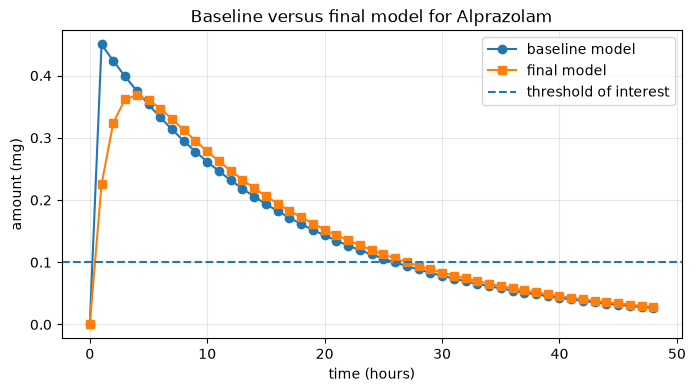

Summary for baseline model
  initial: 0.0
  peak: 0.45
  time_at_peak: 1.0
  final: 0.02647987982293754
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 26.0
  total_time_above_threshold: 25.0
Summary for final model
  initial: 0.0
  peak: 0.368590276270538
  time_at_peak: 4.0
  final: 0.028233977112544027
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 28.0
  total_time_above_threshold: 27.0


In [ ]:
# === TASK 5: compare the baseline and final model ===
# This plot helps you decide what the more detailed model changes.

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t_base * time_step_hours, A_base, marker="o", label="baseline model")
ax.plot(t_final * time_step_hours, amount_final, marker="s", label="final model")
ax.axhline(threshold_amount, linestyle="--", label="threshold of interest")
ax.set_xlabel("time (hours)")
ax.set_ylabel(f"amount ({amount_units})")
ax.set_title(f"Baseline versus final model for {assigned_drug}")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

print_summary(baseline_summary, label="baseline model")
print_summary(final_summary, label="final model")

"""---------------------------------------------------"""
""" Baseline and final model appear similar, however, there are a few differences."""

## Task 6 — Sensitivity or scenario comparison

A model depends on assumptions. Change one meaningful assumption and compare the output. This helps show whether your conclusion is robust or whether it depends strongly on one parameter.

You can change the input schedule, or write `f_alt`, a copy of your `f` with one value changed. If your update rule is linear (Section 9), as the baseline, absorption, and linked models are, changing only the dose rescales the curve, so the time of the peak stays the same. A dose change is most informative for a nonlinear rule such as capacity-limited removal. For a linear rule, consider changing a half-life, the absorption speed, a transfer fraction, or the dose timing instead.

**Report issues to address:** identify the changed assumption, explain why it is scientifically meaningful, and describe whether the model conclusion changed.

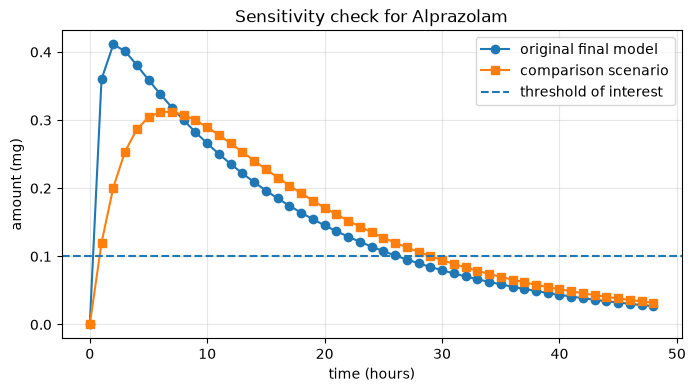

Summary for original final model
  initial: 0.0
  peak: 0.4109424617336008
  time_at_peak: 2.0
  final: 0.026897648565339865
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 27.0
  total_time_above_threshold: 26.0
Summary for comparison scenario
  initial: 0.0
  peak: 0.31227920860206926
  time_at_peak: 7.0
  final: 0.031935967889749096
  first_time_above_threshold: 1.0
  time_below_threshold_after_peak: 30.0
  total_time_above_threshold: 29.0
PASS: comparison label has been completed
PASS: comparison produced finite values
PASS: comparison scenario differs from the final model


In [ ]:
# === TASK 6: sensitivity or scenario comparison ===
# Change ONE scientifically meaningful assumption and rerun your final model.
# Examples include dose, timing, half-life, absorption speed, or removal rate.

comparison_label = "absorption speed was reduced by reducing kabs. This would result in a larget Tmax, since a longer time period would be required to reach mac concentration"

# Option 1 (default): change the input schedule. Here each dose is 50 percent larger.
input_events_alt = input_events
D_alt = make_input_array(T, input_events_alt)

# Option 2: change one parameter. Replace the line f_alt = f with a copy of
# your function f, renamed f_alt, that uses the changed value. Give the changed
# value a new name (for example k_abs_alt) so that f itself does not change.
# If you use this option, set input_events_alt = input_events above.
def f_alt(state,dose):
    reservoir, system = state            # current values of the two state variables   

    available = reservoir + dose
    absorbed = (kabs_model/3) * available

    reservoir_next = available - absorbed
    system_next = rho_model * system + F * absorbed

    return [reservoir_next, system_next]

t_alt, states_alt = simulate_update_rule(f_alt, D_alt, A0_final)
amount_alt = states_alt.reshape(len(t_alt), -1)[:, amount_index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t_final * time_step_hours, amount_final, marker="o", label="original final model")
ax.plot(t_alt * time_step_hours, amount_alt, marker="s", label="comparison scenario")
ax.axhline(threshold_amount, linestyle="--", label="threshold of interest")
ax.set_xlabel("time (hours)")
ax.set_ylabel(f"amount ({amount_units})")
ax.set_title(f"Sensitivity check for {assigned_drug}")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

comparison_summary = amount_summary(t_alt * time_step_hours, amount_alt, threshold=threshold_amount)
print_summary(final_summary, label="original final model")
print_summary(comparison_summary, label="comparison scenario")

check_item("comparison label has been completed", "EDIT_ME" not in comparison_label,
           "Describe the assumption changed in this comparison.")
check_item("comparison produced finite values", np.all(np.isfinite(amount_alt)))
check_item("comparison scenario differs from the final model", not np.allclose(amount_alt, amount_final),
           "Change the input schedule or one parameter in f_alt.")

## Task 7 — Final checks before moving results into the report

These checks are about modeling readiness, not mathematical proof. A model can pass these checks and still need careful interpretation. After running the checks, use the checklist below to confirm that your report contains all of the required modeling content.

In [109]:
# === TASK 7: final model checks ===
# These checks do not prove that the model is correct. They help catch common
# modeling and coding mistakes before figures are moved into the report.

check_item("assigned drug is no longer a placeholder", "EDIT_ME" not in assigned_drug)
check_item("model question is no longer a placeholder", "EDIT_ME" not in model_question)
check_item("amount units are no longer a placeholder", "EDIT_ME" not in amount_units)
check_item("threshold note is no longer a placeholder", "EDIT_ME" not in threshold_note)
check_item("input note is no longer a placeholder", "EDIT_ME" not in input_note)
check_item("input schedule contains at least one event", np.sum(D) > 0)
check_item("baseline values are non-negative", np.min(A_base) >= -1e-9)
check_item("final values are non-negative", np.min(amount_final) >= -1e-9)
check_item("final model differs from the baseline", not np.allclose(amount_final, A_base))
check_item("baseline and final model have the same time grid", len(A_base) == len(amount_final))
check_item("sensitivity comparison is labeled", "EDIT_ME" not in comparison_label)
check_item("baseline parameter justification is complete", "EDIT_ME" not in baseline_parameter_note)
check_item("final parameter justification is complete", "EDIT_ME" not in final_parameter_note)


PASS: assigned drug is no longer a placeholder
PASS: model question is no longer a placeholder
PASS: amount units are no longer a placeholder
PASS: threshold note is no longer a placeholder
PASS: input note is no longer a placeholder
PASS: input schedule contains at least one event
PASS: baseline values are non-negative
PASS: final values are non-negative
PASS: final model differs from the baseline
PASS: baseline and final model have the same time grid
PASS: sensitivity comparison is labeled
PASS: baseline parameter justification is complete
PASS: final parameter justification is complete


## Report-ready content checklist

Your final report should include the following modeling content. The task or section in parentheses is where this notebook produces the material for each item.
Your report should not exceed 1,000 words of main text, plus up to 4 figures with captions. Equations, tables and figure captions do not count toward the limit (do not include long calculations). Address every item below.

1. **Question and scenario** (Task 1): the assigned drug and a focused, one-sentence modeling question.
2. **Definitions** (Tasks 1–4): every state variable and parameter with its units, and the length of the time step.
3. **Input schedule** (Task 2): the dose amounts, their timing and route, and where these values come from.
4. **Threshold of interest** (Task 1): what the threshold represents and where it comes from. If it started as a concentration, show the conversion with the volume of distribution.
5. **Baseline model** (Task 3): the equation, the half-life and bioavailability with a source or justification, and one figure.
6. **Final model** (Task 4): why the added feature fits your assigned drug, the update rule $A_{t+1}=f(A_t,D_t)$ written as an equation, the new parameters with a source or justification, and one figure.
7. **Summary computations** (Tasks 3–5): peak amount, time of peak, first time above the threshold, total time above it, and the time it falls back below.
8. **Baseline versus final model** (Task 5): a comparison figure and the main modeling reason for any difference between the curves.
9. **Sensitivity or scenario comparison** (Task 6): the assumption you changed, why it is scientifically meaningful, and whether your conclusion changed.
10. **Equilibria and cobwebs** (Sections 4 and 5): if the same input is added every step, compute the equilibrium, state whether it is stable, and show a cobweb. Otherwise, explain in one or two sentences why this analysis does not apply to your scenario.
11. **Limitations**: what the model leaves out, which parameter values are most uncertain, and how these could affect your conclusion.